# ChronoClone tutorial: identifying metaclones

A metaclone is a group of clones with similar cell-state changes over time. This tutorial uses the Weinreb 2020 dataset and follows the supplied `0010_ChronoClone_Weinreb2020.ipynb` workflow.

We will filter clones, build their cell-state trajectories, identify metaclones, and plot a density UMAP. The included input contains cell metadata and saved UMAP coordinates; it has no preassigned metaclones. See the [data notes](../examples/weinreb/data/README.md) for its source and filtering history.

## Setup

Run this notebook from a clone of the repository. The [example guide](../examples/weinreb/README.md) explains installation.

Recorded MacBook environment: **chronoclone** at `/Users/HiroMacBook/Documents/ChronoClone/.runtime/chronoclone`, kernel **chronoclone-paper**. This existing environment is reused without changing installed packages. The next cell prints the Python and package versions and the local execution command.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, tempfile
from importlib.metadata import version
sys.dont_write_bytecode = True
os.environ.setdefault('NUMBA_CACHE_DIR', str(Path(tempfile.gettempdir())/'chronoclone-numba-cache'))
# Find the package checkout when run from either tutorial location.
parents = [Path.cwd(), *Path.cwd().parents]
REPO = next(q for p in parents for q in (p, p/'ChronoClone')
            if (q/'chronoclone/__init__.py').is_file())
sys.path.insert(0, str(REPO))
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.neighbors import NearestNeighbors
from IPython.display import display
import chronoclone as cc
sc.settings.n_jobs = os.cpu_count() or 1
DAYS = [2, 4, 6]
DATA = REPO/'examples/weinreb/data'
OUT = REPO/'examples/weinreb/results'
OUT.mkdir(parents=True, exist_ok=True)
versions = {name:version(name) for name in ['numpy','pandas','scipy','anndata','scanpy',
            'scikit-learn','matplotlib','igraph','leidenalg']}
versions['chronoclone'] = cc.__version__
print({'environment':'chronoclone','path':sys.prefix,'kernel':'chronoclone-paper',
       'manager':'Existing installation reused through a local alias',
       'python':sys.version.split()[0],'available_cores':os.cpu_count()})
display(pd.Series(versions, name='version').to_frame())
print('Original MacBook execution command:')
print(f'JUPYTER_PATH=/Users/HiroMacBook/Documents/ChronoClone/.runtime/jupyter {sys.executable} -m nbconvert --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper --ExecutePreprocessor.timeout=1800 {REPO}/notebooks/chronoclone_tutorial.ipynb')


{'environment': 'chronoclone', 'path': '/Users/HiroMacBook/Documents/ChronoClone/.runtime/chronoclone', 'kernel': 'chronoclone-paper', 'manager': 'Existing installation reused through a local alias', 'python': '3.11.15', 'available_cores': 12}


,version
numpy,2.4.6
pandas,2.3.3
scipy,1.17.1
anndata,0.12.18
scanpy,1.11.5
scikit-learn,1.9.0
matplotlib,3.11.0
igraph,1.0.0
leidenalg,0.12.0
chronoclone,0.1.0


Original MacBook execution command:
JUPYTER_PATH=/Users/HiroMacBook/Documents/ChronoClone/.runtime/jupyter /Users/HiroMacBook/Documents/ChronoClone/.runtime/chronoclone/bin/python -m nbconvert --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper --ExecutePreprocessor.timeout=1800 /Users/HiroMacBook/Documents/ChronoClone/ChronoClone/notebooks/chronoclone_tutorial.ipynb


## 1. Load the cell data

Restore the recorded category order and UMAP coordinates. Gene-expression values are unnecessary for identifying metaclones from these cell-state annotations.

In [2]:
provenance = json.loads((DATA/'provenance.json').read_text())
input_path = DATA/provenance['payload']['file']
input_sha = hashlib.sha256(input_path.read_bytes()).hexdigest()
assert input_sha == provenance['payload']['sha256']
cells = pd.read_csv(input_path, **provenance['extraction']['read_csv']).set_index('cell_id')
for column, schema in provenance['extraction']['source_categorical_schema'].items():
    cells[column] = pd.Categorical(cells[column], categories=schema['categories'], ordered=schema['ordered'])
assert cells.index.is_unique and cells['LARRY_ID'].notna().all()
obs = cells[['LARRY_ID','day','cell_type']].copy()
obs['day'] = obs['day'].astype(int)
obs['condition'] = 'Weinreb'
adata = ad.AnnData(X=sparse.csr_matrix((len(obs),0),dtype=np.float32), obs=obs)
adata.obsm['X_umap'] = cells[['UMAP1','UMAP2']].to_numpy(dtype=np.float32)
print(f'{adata.n_obs:,} cells; {adata.obs.LARRY_ID.nunique():,} clones')
display(adata.obs.groupby('day',observed=True).size().rename('cells').to_frame())


9,714 cells; 784 clones


,cells
day,
2,1041
4,3301
6,5372


## 2. Keep clones with consecutive recovery

Start with Day-2 progenitor states `prog_1` and `prog_2`, and require recovery at two or more consecutive time points. The included cohort has already passed this filter; this step checks it again.

In [3]:
adata_filtered = cc.filter_lineage_continuity(
    adata, condition_key='condition', condition_val='Weinreb', day_key='day',
    cell_type_key='cell_type', start_cell_type=['prog_1','prog_2'],
    barcode_key='LARRY_ID', min_persistence=2)
print(f'{adata_filtered.n_obs:,} cells; {adata_filtered.obs.LARRY_ID.nunique():,} clones after filtering')


Starting lineage filtration for Condition: 'Weinreb'...
Start cell type(s): {'prog_2', 'prog_1'}
Detected time points: [np.int64(2), np.int64(4), np.int64(6)]
Valid Start barcodes at Day 2: 784
Barcodes passing continuity filter (min 2 timepoints): 784

VERIFICATION REPORT
Original Cells : 9714
Filtered Cells : 9714 (100.00%)

Day 2 Composition:
cell_type
prog_2                    786
prog_1                    255
prog_Mono                   0
prog_Meg_Ery                0
prog_Ly_pDC                 0
prog_DC_Mono                0
prog_Baso_Meg_Ery_Mast      0
prog_Baso_Eos               0
prog_4                      0
prog_3                      0
Baso                        0
DC                          0
early_prog_Neu              0
Neu                         0
Mono                        0
Meg                         0
Mast                        0
Ly                          0
Ery                         0
Eos                         0
prog_Neu                    0
Name: count,

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/preprocessing.py:150: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(barcode_key)[day_key]


## 3. Build and normalize clone trajectories

Count cells for each clone, day, and cell state. Then divide by each clone's total cell count at that day. The resulting vector describes how the clone's cell-state composition changes over time.

In [4]:
states = sorted(str(x) for x in adata_filtered.obs['cell_type'].unique())
clone_table = cc.build_clone_table(
    adata_filtered, clone_id_col='LARRY_ID', time_col='day', feature_col='cell_type',
    time_prefix='Day', feature_prefix='', times_order=DAYS, features_order=states,
    min_total_count=0)
normalized = cc.normalize_clone_table(
    clone_table, times_order=[f'Day{day}' for day in DAYS], features_order=states,
    time_prefix='Day', feature_prefix='')
for day in DAYS:
    totals = normalized.filter(regex=f'^Day{day}_').sum(axis=1)
    assert np.all(np.isclose(totals,0) | np.isclose(totals,1))
print(f'{len(normalized):,} clones × {len(normalized.columns)} trajectory features')
display(normalized.iloc[:5,:8])


784 clones × 44 trajectory features


/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/preprocessing.py:260: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby([clone_id_col, feature_col])
/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/preprocessing.py:260: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby([clone_id_col, feature_col])
/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/preprocessing.py:260: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to ad

,Day2_prog_1,Day2_prog_2,Day4_Baso,Day4_DC,Day4_Eos,Day4_Ery,Day4_Ly,Day4_Mast
LARRY_ID,,,,,,,,
Clone_10,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
Clone_15,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0
Clone_21,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0
Clone_38,0.333333,0.666667,0.0,0.0,0.0,0.0,0.0,0.0
Clone_50,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0


## 4. Build a consensus matrix

Keep clones with at least three cells. Run Leiden clustering at several resolutions and count how often each pair of clones is grouped together. The seed is fixed for reproducibility.

In [5]:
resolutions = np.arange(1.1,4.1,0.1)
filtered_table, trajectory_adata, consensus = cc.build_consensus_matrix(
    normalized, min_cells=3, adata_full=adata_filtered, clone_id_col='LARRY_ID',
    n_neighbors=30, resolutions=resolutions, random_state=0)
distance = 1-consensus
assert np.allclose(consensus,consensus.T) and np.allclose(np.diag(consensus),1)
assert (distance>=0).all() and (distance<=1).all()
print(f'Consensus matrix: {consensus.shape[0]} × {consensus.shape[1]} clones')


/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/consensus.py:62: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  clone_counts = adata_full.obs.groupby(clone_id_col).size()


/Users/HiroMacBook/Documents/ChronoClone/.runtime/chronoclone/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/chronoclone/consensus.py:79: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


Consensus matrix: 713 × 713 clones


## 5. Select a clustering threshold

Evaluate distance thresholds from 0.01 to 0.90. ChronoClone selects the threshold with the highest mean silhouette score on the normalized trajectories.

In [6]:
threshold_grid = np.arange(0.01,0.91,0.01)
thresholds, scores, cluster_counts, threshold, labels, clone_silhouettes = cc.sweep_thresholds(
    distance, filtered_table, thresholds=threshold_grid)
sweep = pd.DataFrame({'threshold':thresholds,'silhouette':scores,'metaclones':cluster_counts})
sweep.to_csv(OUT/'threshold_sweep.csv', index=False)
display(sweep.loc[np.isclose(sweep.threshold,threshold)])


Starting threshold sweep...



Selected threshold : 0.73
Max silhouette score: 0.247
Clusters            : 23


,threshold,silhouette,metaclones
72,0.73,0.246683,23


The plot shows the threshold selection.

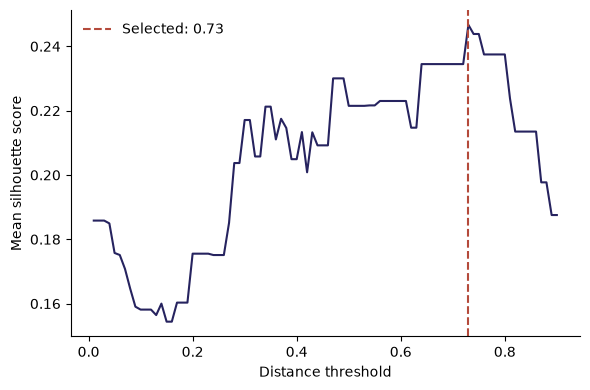

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/threshold_sweep


In [7]:
# Plot the computed threshold sweep.
plot_data = sweep.sort_values('threshold')
with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig, ax = plt.subplots(figsize=(6,4))
    ax.plot(plot_data.threshold,plot_data.silhouette,color='#26235F',lw=1.5)
    ax.axvline(threshold,color='#B44A3B',ls='--',label=f'Selected: {threshold:.2f}')
    ax.set(xlabel='Distance threshold',ylabel='Mean silhouette score')
    ax.spines[['top','right']].set_visible(False)
    ax.legend(frameon=False)
    fig.tight_layout()
    stem = OUT/'threshold_sweep'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.pdf'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=200,bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


## 6. Keep supported metaclones

Keep clones with silhouette scores of at least −0.1 whose original cluster contains at least 15 clones. Count cluster size before filtering individual clones. Number the retained metaclones consecutively and transfer their labels back to cells.

In [8]:
cluster_sizes = pd.Series(labels).value_counts()
size_per_clone = pd.Series(labels).map(cluster_sizes).to_numpy()
keep = (clone_silhouettes >= -0.1) & (size_per_clone >= 15)
label_map = {int(label):i+1 for i,label in enumerate(sorted(np.unique(labels[keep])))}
metaclones = np.array([label_map[int(label)] for label in labels[keep]])
adata = cc.transfer_metaclone_labels(
    adata.copy(), trajectory_adata[keep].copy(), metaclones,
    clone_id_col='LARRY_ID', target_col='metaclone')
assignments = pd.DataFrame({
    'LARRY_ID':filtered_table.index.astype(str), 'raw_cluster':labels,
    'silhouette':clone_silhouettes, 'cluster_size_before_filter':size_per_clone,
    'passes_silhouette':clone_silhouettes>=-0.1, 'passes_cluster_support':size_per_clone>=15,
    'retained':keep,
    'metaclone':[label_map.get(int(label),-1) if retained else -1 for label,retained in zip(labels,keep)]})
assignments.to_csv(OUT/'clone_assignments.csv',index=False)
support = (adata.obs.dropna(subset=['metaclone']).groupby('metaclone',observed=True)
           .agg(clones=('LARRY_ID','nunique'),cells=('LARRY_ID','size')))
summary = {'input_sha256':input_sha,'versions':versions,'seed':0,
    'input_cells':adata.n_obs,'input_clones':int(adata.obs.LARRY_ID.nunique()),
    'consensus_clones':len(filtered_table),'selected_threshold':float(threshold),
    'raw_metaclones':len(np.unique(labels)),'retained_clones':int(keep.sum()),
    'displayed_metaclones':len(support),'assigned_cells':int(adata.obs.metaclone.notna().sum()),
    'support_gates':{'minimum_silhouette':-0.1,'minimum_cluster_clones_before_silhouette':15},
    'identification':{'neighbors':30,'resolutions':resolutions.tolist(),'thresholds':threshold_grid.tolist()},
    'plot':{'density':'same-metaclone-and-day count among nearest cells','neighbors':100,
            'neighbor_reference':'all','scale':'per metaclone across displayed days, minimum vmax 5','time_order':DAYS},
    'label_scope':'IDs identify this reproducible package tutorial fit.'}
(OUT/'example_summary.json').write_text(json.dumps(summary,indent=2)+'\n')
print(f'{keep.sum()} clones in {len(support)} metaclones')
display(support)


566 clones in 18 metaclones


,clones,cells
metaclone,,
1.0,86,1525
2.0,19,116
3.0,25,387
4.0,40,551
5.0,41,567
6.0,21,166
7.0,32,1209
8.0,27,265
9.0,35,639


## 7. Plot a density UMAP

Rows are days and columns are metaclones. Gray points show all cells. Color counts how many of a cell's 100 nearest neighbors share its metaclone and day. Neighbors are selected from all cells. Each metaclone column shares one color scale across days; `n` is its number of clones.

The cell below shows the calculation and figure construction. It adds no lineage labels or family bars.

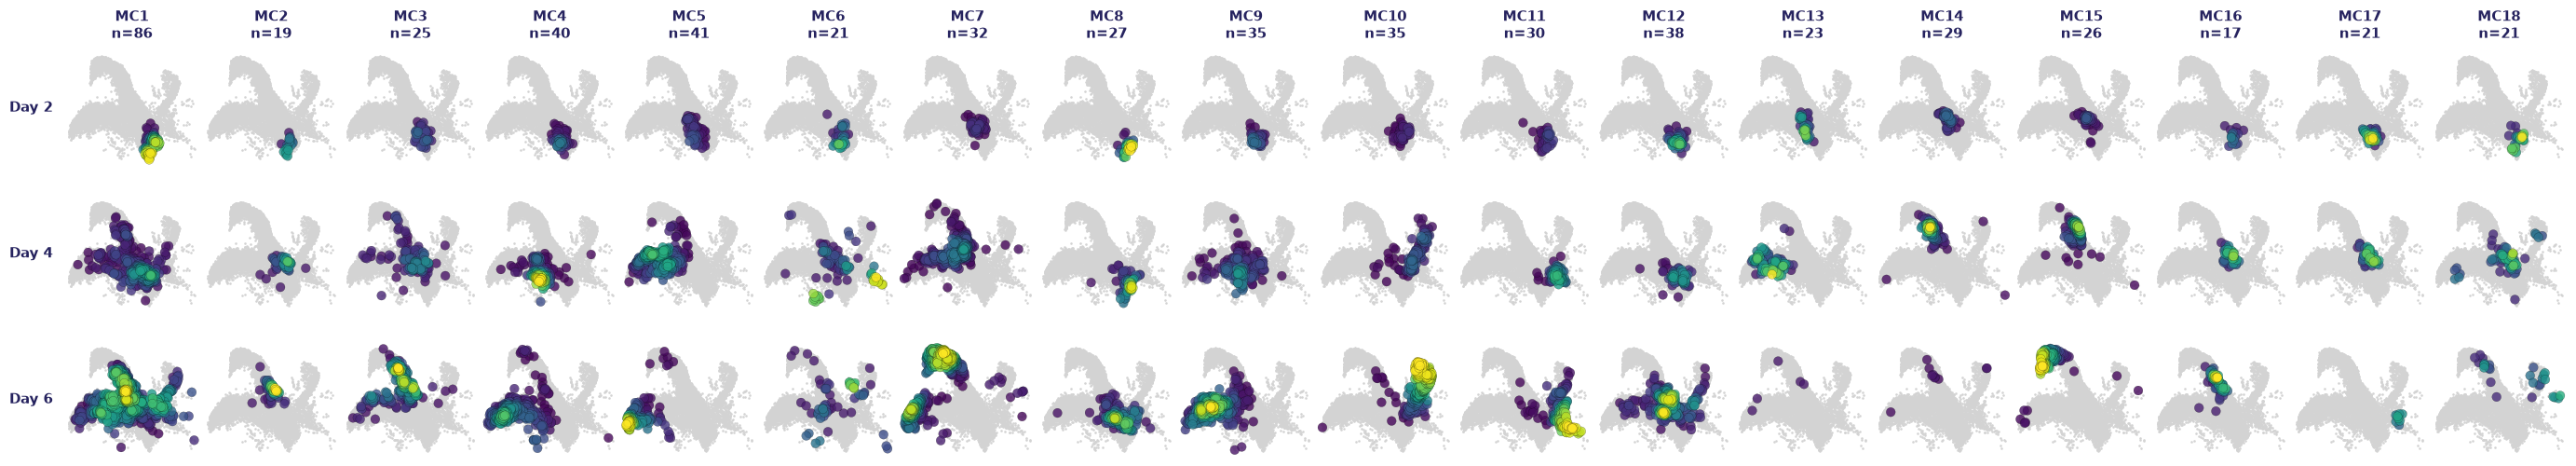

/Users/HiroMacBook/Documents/ChronoClone/ChronoClone/examples/weinreb/results/weinreb_metaclone_density_umap


In [9]:
# Calculate local density on the stored UMAP.
U = np.asarray(adata.obsm['X_umap'],dtype=float)
mc = adata.obs.metaclone
mc_order = sorted(mc.dropna().unique())
neighbor_index = NearestNeighbors(n_neighbors=min(100,len(U)),algorithm='ball_tree').fit(U)
neighbors = neighbor_index.kneighbors(U,return_distance=False)
groups, maxima = {}, {}
for m in mc_order:
    maxima[m] = 5
    for day in DAYS:
        mask = (mc.eq(m) & adata.obs.day.eq(day)).fillna(False).to_numpy(dtype=bool)
        density = mask[neighbors[mask]].sum(axis=1)
        groups[m,day] = (U[mask],density)
        if len(density): maxima[m] = max(maxima[m],density.max())

# Draw days × metaclones with one color scale per column.
with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    size = (1.55*len(mc_order),5.5)
    fig, axes = plt.subplots(len(DAYS),len(mc_order),figsize=size,squeeze=False)
    low, high = U.min(axis=0)-1, U.max(axis=0)+1
    for column,m in enumerate(mc_order):
        n_clones = adata.obs.loc[mc.eq(m),'LARRY_ID'].nunique()
        for row,day in enumerate(DAYS):
            ax = axes[row,column]
            ax.scatter(U[:,0],U[:,1],s=3.5,c='lightgrey',lw=0,rasterized=True,zorder=0)
            coordinates,density = groups[m,day]
            if len(density):
                order = np.argsort(density,kind='stable')
                ax.scatter(coordinates[order,0],coordinates[order,1],c=density[order],
                    cmap='viridis',s=50,alpha=0.8,edgecolors='black',linewidths=0.15,
                    vmin=0,vmax=maxima[m],rasterized=False,zorder=2)
            ax.set_aspect('equal')
            ax.set_xlim(low[0],high[0]); ax.set_ylim(low[1],high[1])
            ax.axis('off')
            if column==0:
                ax.text(-0.08,0.5,f'Day {day}',transform=ax.transAxes,fontsize=11,
                        color='#26235F',fontweight='bold',ha='right',va='center')
            if row==0:
                ax.set_title(f'MC{int(m)}\nn={n_clones}',fontsize=11,color='#26235F',fontweight='bold',pad=10)
    fig.subplots_adjust(left=max(0.03,0.62/size[0]),right=1-0.18/size[0],
                        top=1-0.7/size[1],bottom=0.15/size[1],wspace=0.02,hspace=0.03)
    stem = OUT/'weinreb_metaclone_density_umap'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.pdf'),dpi=300,bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=600,bbox_inches='tight')
    display(fig)
plt.close(fig)
print(stem)


## Use the plotting function

The package provides the same density UMAP as a reusable function:

```python
fig, axes = cc.plot_metaclone_density_umap(
    adata, time_order=[2, 4, 6], neighbor_reference="all"
)
fig.savefig("density_umap.svg", bbox_inches="tight")
```

The output folder contains clone assignments, the threshold sweep, the run settings, and both figures. Metaclone IDs refer to this run. The [source notes](../examples/weinreb/data/README.md) explain the saved author workflow and its historical partition.